## Tutorium: PyPSA 2 - Erweiterte Anwendung von Basiskomponenten

In [1]:
import pypsa
import pandas as pd
import numpy as np

E0000 00:00:1793630584.659503     301 instrument.cc:563] Metric with name 'grpc.resource_quota.calls_dropped' registered more than once. Ignoring later registration.
E0000 00:00:1793630584.659570     301 instrument.cc:563] Metric with name 'grpc.resource_quota.calls_rejected' registered more than once. Ignoring later registration.
E0000 00:00:1793630584.659575     301 instrument.cc:563] Metric with name 'grpc.resource_quota.connections_dropped' registered more than once. Ignoring later registration.
E0000 00:00:1793630584.659578     301 instrument.cc:563] Metric with name 'grpc.resource_quota.instantaneous_memory_pressure' registered more than once. Ignoring later registration.
E0000 00:00:1793630584.659580     301 instrument.cc:563] Metric with name 'grpc.resource_quota.memory_pressure_control_value' registered more than once. Ignoring later registration.


### 2.3 Invertierter Generator als optimierbare Last

Generatoren können als Last in einem Netzwerk dienen, indem das Argument `sign` auf `sign=-1` gesetzt wird. Die Differenz zur Load Komponente liegt darin, dass PyPSA die **Last pro Snapshot** selbst optimiert. Diese Last ist keine Randbedingung mehr, sondern besitzt Variablen, die PyPSA für die Optimierung ideal setzen kann. Äquivalent zum normalen Generator kann `p_nom_extendable=True` gesetzt werden, sodass PyPSA zusätzlich die Nennlast optimieren kann. 

Gegeben ist folgendes Netzwerk:

In [2]:
network = pypsa.Network()

df_data = pd.read_csv('data_PyPSA_T1.csv')

network.set_snapshots(df_data.index)

network.add("Bus", "electricity")
network.add("Bus", "hydrogen_30bar")
network.add("Bus", "hydrogen_150bar")

network.add('Generator', name='grid_supply', bus='electricity', carrier="grid_supply", p_nom=np.inf, marginal_cost=0.3)
network.add('Generator', name='pv', bus='electricity', carrier="pv", p_nom=10000, p_max_pu=df_data["PV Erzeugung"]) # Bestehende PV-Anlage mit 100 kW.

/opt/conda/lib/python3.13/site-packages/pypsa/network/io.py:2082: FutureWarning: pandas infers the `str` dtype for string data since its version 3.0. PyPSA still converts it back to numpy object dtype on import, but will keep it from PyPSA 2.0 on. Set `pypsa.options.api.legacy_string_dtype` explicitly to suppress this warning.
  new_static = _coerce_string_dtypes(new_static)


Sie wollen ihren grünen Wasserstoff an Kunden veraufen, müssen aber daür eine Wasserstoffleitung bauen. Fügen Sie dafür dem Bus `hydrogen_30bar` einen invertierten Generator zu. Pro Kilogramm Wasserstoff den die Leitung in der Stunde transportieren soll, liegen die Investitionskosten als Annuität bei 500 €/kg_H2a. Der Erlös liegt bei 6 €/kg_H2

In [3]:
network.add('Generator', name='h2_pipe', bus='hydrogen_30bar', p_nom_extendable=True, sign=-1, marginal_cost=-6, capital_cost=500)

### 2.2 Multilink

Während ein Link als Default zwei Busse miteinander verbindet, können beliebig viele weitere Busse der Verbindung hinzugefügt werden. Dabei werden die Busse als weitere Argumente mitgeliefert, nach den immer benötigten `bus0` und `bus1` können demnach `bus2`, `bus3` etc. als Argumente hinzugefügt werden. 

PyPSA geht davon aus, dass die weiteren Busse weitere Outputs darstellen. Jede Verbindung von Input zu Output hat dabei eine eigene Effizienz: `efficiency`, `efficiency2`, `efficiency3`.

Soll ein Bus einen weiteren Input darstellen, muss die dazugehörige Effizienz negativ sein. Die Effizienz bezieht sich trotzdem weiterhin auf `bus0`. Beispiel: `bus2` ist ein weiterer Input, somit muss die Effizienz von `bus0` zu `bus2` negativ in `efficiency2` angegeben werden.

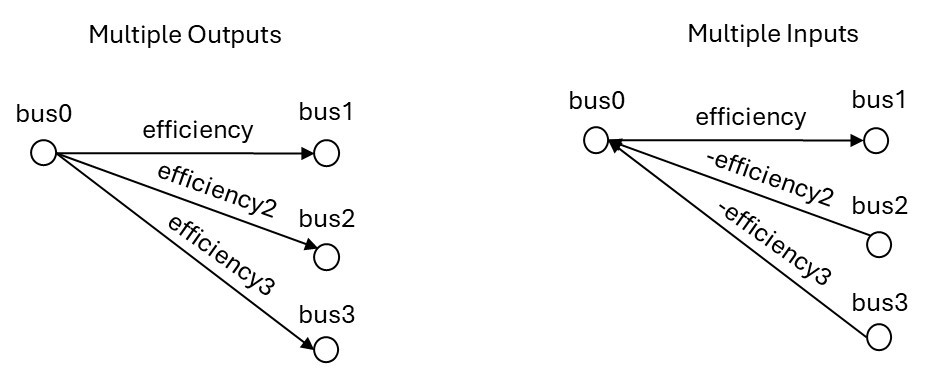

In [4]:
network.add("Bus", "water")

network.add('Generator', name='water_supply', bus='water', carrier="water", p_nom=np.inf, marginal_cost=0.1)

Fügen Sie dem Netzwerk Elektrolyseur hinzu, dessen Größe von PyPSA optimiert werden soll. Dieser hat die als Input-Busse `el_site` und `water`, und als Output-Bus `hydrogen_30bar`. Die Investitionskosten als Annuität liegen bei 250 € pro kW Nennleistung. Außerdem gilt: 
- 50 kWh für 1 kg H2 -> 2 % "Effizienz"
- 10 kg Wasser für 1 kg H2 -> Welche "Effizienz" benötigt man nun für `efficiency2`?


In [5]:
network.add("Link", name="electrolyser", bus0="electricity", bus1="hydrogen_30bar", bus2="water",  carrier="elyzer", p_nom_extendable=True, efficiency=0.02, efficiency2=-0.2, capital_cost=250)

### 2.2 Store & Link als kombinierter Speicher

Wie bereits angemerkt, wird, wenn das Ein- und Ausspeichern nicht die gleiche Leistung hat, eine Store Komponente mit zwei Links verwendet.

Fügen Sie dem Netzwerk einen Wasserstoffspeicher hinzu. Der Wasserstoff wird dazu auf 150 bar verdichtet. PyPSA soll dabei die Größe von Speicher, Verdichter und Expansionsturbine optimieren. Der Verdichter benötigt Strom. 
- Speicher 
    - Standverluste: 0.1 % pro Stunde
    - Annuität: 20 €/kg_H2
- Verdichter
    - Keine Verluste von H2 beim der Kompression
    - Strom pro kg/h H2: 1.1 kWh/kg -> 91% "Effizienz"
    - Annuität: 100 €/kg_H2/h
- Expansionsventil
    - Annuität: 5 €/kg_H2/h
    - Keine Verluste von H2 beim der Expansion

In [6]:
network.add("Store", "h2_storage", bus="hydrogen_150bar", carrier="store", e_nom_extendable=True, standing_loss=0.001, capital_cost=20)
network.add("Link", "h2_compressor", carrier="compressor", bus0="hydrogen_30bar", bus1="hydrogen_150bar", bus2="electricity", p_nom_extendable=True, efficiency=1, efficiency2=-0.91, capital_cost=100)
network.add("Link", "h2_expander", bus0="hydrogen_150bar", carrier="expand", bus1="hydrogen_30bar", efficiency=1, p_nom_extendable=True, capital_cost=5)

Optimieren Sie das Modell:

In [7]:
network.optimize(solver_name='gurobi')

/tmp/ipykernel_301/3854944838.py:1: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  network.optimize(solver_name='gurobi')
Index(['electricity', 'hydrogen_30bar', 'hydrogen_150bar', 'water'], dtype='object', name='name')
Index(['grid_supply', 'pv', 'water_supply'], dtype='object', name='name')
Index(['electrolyser', 'h2_compressor', 'h2_expander'], dtype='object', name='name')
Index(['h2_storage'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Gurobi solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 7/7 [00:00<00:00, 208.93it/s]
INFO:linopy.io: Writing time: 0.28s


Set parameter ServerTimeout to value 10


INFO:gurobipy:Set parameter ServerTimeout to value 10


Set parameter TokenServer to value "139.6.183.241"


INFO:gurobipy:Set parameter TokenServer to value "139.6.183.241"


Read LP format model from file /tmp/linopy-problem-jzsqiztl.lp


... (209 outputs left out)

INFO:gurobipy:Solved in 11161 iterations and 13.94 seconds (2.58 work units)


Optimal objective -1.121772232e+05


INFO:gurobipy:Optimal objective -1.121772232e+05
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 79061 primals, 184469 duals
Objective: -1.12e+05
Solver: gurobi
Runtime: 13.94s
Dual bound: -1.12e+05
Solver model: available
Solver message: 2

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Generator-ext-p-lower, Generator-ext-p-upper, Link-ext-p-lower, Link-ext-p-upper, Store-ext-e-lower, Store-ext-e-upper, Store-energy_balance were not assigned to the network.


('ok', 'optimal')

Geben Sie sich den jährlichen Gewinn, die optimierten Kapazitäten, die Investitionskosten und die Betriebskosten aus. 

In [8]:
print(network.objective)

results = network.statistics()

print(results["Optimal Capacity"])
print(results["Capital Expenditure"])
print(results["Operational Expenditure"])
print(results["Revenue"])

-112177.22324558086
Generator  -                 27.65594
           grid_supply            inf
           pv             10000.00000
           water                  inf
Link       compressor         8.44045
           elyzer          1804.81919
           expand            24.40594
Store      store             92.38209
Name: Optimal Capacity, dtype: float64
Generator  -               13827.96828
           grid_supply         0.00000
           pv                  0.00000
           water               0.00000
Link       compressor        844.04473
           elyzer         451204.79824
           expand            122.02968
Store      store            1847.64171
Name: Capital Expenditure, dtype: float64
Generator  -             -696215.43059
           grid_supply         0.00000
           pv                  0.00000
           water          116191.72470
Link       compressor          0.00000
           elyzer              0.00000
           expand              0.00000
Store     

Erstellen Sie einen Plot, der kg_H2/h für den Elektrolyseur, den Kompressor, das Expansionsventil und die Wasserstoffleitung für zwei beliebige Tage darstellt.

In [9]:
# h2_plot = pd.DataFrame()
# h2_plot["Elektrolyseur"] = -network.links_t.p1["electrolyser"]
# h2_plot["Kompressor"] = network.links_t.p0["h2_compressor"]
# h2_plot["Expansionsventil"] = -network.links_t.p1["h2_expander"]
# h2_plot["Wasserstoffleitung"] = network.generators_t.p["h2_pipe"]

# h2_plot.loc[4000:4048].plot.area()

network.statistics.energy_balance()

component  carrier     bus_carrier
Generator  -           AC            -1.160359e+05
           pv          AC             5.830187e+06
           water       AC             1.161917e+06
Link       compressor  AC            -2.060030e+04
           elyzer      AC            -6.855312e+06
Store      store       AC            -1.558196e+02
dtype: float64

In [10]:
c = network.components.generators.static

In [11]:
c.p_nom_opt

name
grid_supply              inf
pv              1.000000e+04
h2_pipe         2.765594e+01
water_supply             inf
Name: p_nom_opt, dtype: float64

In [12]:
network.components.generators.static

,bus,control,type,p_nom,p_nom_mod,p_nom_extendable,p_nom_min,p_nom_max,p_nom_set,p_min_pu,...,min_down_time,up_time_before,down_time_before,ramp_limit_up,ramp_limit_down,ramp_limit_start_up,ramp_limit_shut_down,weight,p_nom_opt,capital_cost_piecewise_opt
name,,,,,,,,,,,,,,,,,,,,,
grid_supply,electricity,Slack,,inf,0.0,False,0.0,inf,NaN,0.0,...,0,1,0,NaN,NaN,NaN,NaN,1.0,inf,0.0
pv,electricity,PQ,,10000.0,0.0,False,0.0,inf,NaN,0.0,...,0,1,0,NaN,NaN,NaN,NaN,1.0,1.000000e+04,0.0
h2_pipe,hydrogen_30bar,Slack,,0.0,0.0,True,0.0,inf,NaN,0.0,...,0,1,0,NaN,NaN,NaN,NaN,1.0,2.765594e+01,0.0
water_supply,water,Slack,,inf,0.0,False,0.0,inf,NaN,0.0,...,0,1,0,NaN,NaN,NaN,NaN,1.0,inf,0.0


In [22]:
network.components

PyPSA Components Store
- 4 'Bus' Components
- 0 'Carrier' Components
- 4 'Generator' Components
- 0 'Load' Components
- 3 'Link' Components
- 1 'Store' Components
- 0 'StorageUnit' Components
- 0 'Line' Components
- 59 'LineType' Components
- 0 'Process' Components
- 0 'Transformer' Components
- 14 'TransformerType' Components
- 0 'ShuntImpedance' Components
- 0 'GlobalConstraint' Components
- 0 'Shape' Components
- 4 'SubNetwork' Components